### 线性回归房价预测

In [2]:
# 房价跟一些列有关系：面积、位置、房间布局……
import numpy as np

from sklearn import datasets

from sklearn.linear_model import LinearRegression

#### 加载数据

In [3]:
boston = datasets.load_boston()

X = boston['data'] # 数据，这些数据影响了房价，统计指标
y = boston['target'] # 房价，24表示24万美金

# CRIM 犯罪
# NOX 空气污染
# TAX 税收
# 这些指标都和房价有关系
feature_names = boston['feature_names'] # 具体指标
feature_names

array(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD',
       'TAX', 'PTRATIO', 'B', 'LSTAT'], dtype='<U7')

In [4]:
boston

{'data': array([[6.3200e-03, 1.8000e+01, 2.3100e+00, ..., 1.5300e+01, 3.9690e+02,
         4.9800e+00],
        [2.7310e-02, 0.0000e+00, 7.0700e+00, ..., 1.7800e+01, 3.9690e+02,
         9.1400e+00],
        [2.7290e-02, 0.0000e+00, 7.0700e+00, ..., 1.7800e+01, 3.9283e+02,
         4.0300e+00],
        ...,
        [6.0760e-02, 0.0000e+00, 1.1930e+01, ..., 2.1000e+01, 3.9690e+02,
         5.6400e+00],
        [1.0959e-01, 0.0000e+00, 1.1930e+01, ..., 2.1000e+01, 3.9345e+02,
         6.4800e+00],
        [4.7410e-02, 0.0000e+00, 1.1930e+01, ..., 2.1000e+01, 3.9690e+02,
         7.8800e+00]]),
 'target': array([24. , 21.6, 34.7, 33.4, 36.2, 28.7, 22.9, 27.1, 16.5, 18.9, 15. ,
        18.9, 21.7, 20.4, 18.2, 19.9, 23.1, 17.5, 20.2, 18.2, 13.6, 19.6,
        15.2, 14.5, 15.6, 13.9, 16.6, 14.8, 18.4, 21. , 12.7, 14.5, 13.2,
        13.1, 13.5, 18.9, 20. , 21. , 24.7, 30.8, 34.9, 26.6, 25.3, 24.7,
        21.2, 19.3, 20. , 16.6, 14.4, 19.4, 19.7, 20.5, 25. , 23.4, 18.9,
        35.4, 24.7, 3

#### 数据查看

In [5]:
# 506表示506统计样本
# 影响房价的13个属性
X.shape

(506, 13)

In [6]:
# 506个房子，对应着506价格
# X ---> y一一对应
# 数据--->目标值对应
y.shape

(506,)

#### 数据拆分

In [7]:
# 506个数据、样本
# 拆分成两份：一份80%，训练数据；20%，验证数据
# 拿出其中的80%，交给算法，线性回归，学习、总结、拟合函数
# 20%，作用：验证，测一测，看看算法，学习80%结束，是否准确！
index = np.arange(506)
np.random.shuffle(index)

train_index = index[:405]
test_index = index[405:]

In [8]:
# 80% 训练数据
X_train = X[train_index]
y_train = y[train_index]
display(X_train.shape,y_train.shape)

(405, 13)

(405,)

In [9]:
# 20% 测试数据
X_test = X[test_index]
y_test = y[test_index]

display(X_test.shape,y_test.shape)

(101, 13)

(101,)

#### 数据建模（model本质就是方程）

In [10]:
np.set_printoptions(suppress = True)

model = LinearRegression(fit_intercept = True)

# 如何构建，模：算法、方程
# 考试，做过的题
model.fit(X_train,y_train)

# 建模获取了斜率，有大有小，有正有负，表示什么？
# 正：正相关，面积，越大，房价越高
# 负：刚好相反，犯罪率，环境污染
display(model.coef_,model.intercept_)

array([ -0.11731532,   0.04995292,  -0.01857529,   3.34956943,
       -18.21369577,   3.37713271,  -0.00130705,  -1.60329627,
         0.34146965,  -0.01314971,  -0.89497252,   0.00793864,
        -0.55246794])

40.25222043664879

In [11]:
feature_names

array(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD',
       'TAX', 'PTRATIO', 'B', 'LSTAT'], dtype='<U7')

#### 模型验证、应用

In [12]:
# 模型预测结果：y_
y_ = model.predict(X_test).round(2)
y_[:30]

array([35.83, 18.83, 22.6 , 34.19, 33.08, 24.32, 30.26, 10.84, 27.91,
       28.96, 20.08, 17.19, 27.2 , 31.31, 19.55, 18.62,  7.48, 24.25,
       19.06, 19.72, 17.67, 26.95, 20.89, 14.7 ,  9.13, 40.31, 25.37,
       22.33, 20.32, 25.58])

In [13]:
y_test[:30]

array([33.4, 14.1, 20.6, 34.6, 27. , 22.6, 34.7, 16.5, 26.6, 26.4, 20.1,
       13. , 22. , 28.4, 19.2, 16. ,  7. , 24.4, 19.9, 18.5,  7.2, 20.6,
       24.5,  8.4, 17.8, 48.8, 22.9, 22.2, 22.9, 24. ])

#### 模型评估

In [14]:
# 判断一下，训练数据 80%的数据的评分
# 为什么使用，训练数据，评分高？？？
# 做过题目，再次参加考试，分数高
model.score(X_train,y_train)

0.7286467439553891

In [15]:
# 最大值，是1，小于0
# 模型特别不好，那么评分可以是负数
# 这个指标越接近1，说明算法越优秀~
# 相当于，没见过题目，新题
model.score(X_test,y_test)

0.7873013527459047

$R^2 = 1 - \frac{u}{v}$

`u` is the residual sum of squares ``((y_true - y_pred)
** 2).sum()`

`v` is the total sum of squares ``((y_true -
y_true.mean()) ** 2).sum()``

In [16]:
y_pred = model.predict(X_test)
y_true = y_test

In [17]:
u = ((y_true - y_pred)**2).sum()
u 

1593.8657369073653

In [18]:
v = ((y_true - y_true.mean())**2).sum()
v

7493.539603960396

In [19]:
1 - u/v

0.7873013527459047

In [20]:
# 最小二乘法
from sklearn.metrics import mean_squared_error

In [21]:
# 这个是测试数据，验证数据，表现，误差
# 对应那20%
mean_squared_error(y_true,y_pred)

15.780848880270943

In [22]:
# 80% 训练，表现
mean_squared_error(y_train,model.predict(X_train))

23.593403772579354

### 代码模拟梯度下降

In [23]:
import matplotlib.pyplot as plt

#### 构建函数和导函数

In [24]:
# 构建方程
f = lambda x : (x - 3.5)**2 - 4.5*x + 10

# 导函数
g = lambda x :2 * (x - 3.5) - 4.5

#### 函数可视化

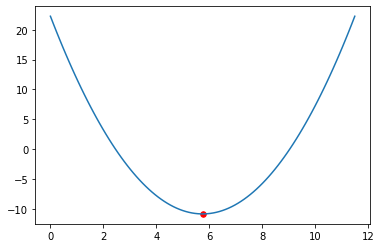

In [25]:
x = np.linspace(0,11.5,100)

y = f(x)

plt.plot(x,y)

plt.scatter(5.75,f(5.75),color = 'red',s = 30)

#### 求这个方程的最小值

如果有方程，那么使用方程求导，非常方便！

In [26]:
# 求导函数，令导函数为0，求解最小值对应的x值

In [27]:
# 2 * (x - 3.5) - 4.5
# 2*x - 11.5 = 0
# 2x = 11.5
# x = 5.75

#### 梯度下降（不能令方程的导函数为0，进行求解）

-----------------随机x是： 0
+++++++++++++++梯度下降次数： 13


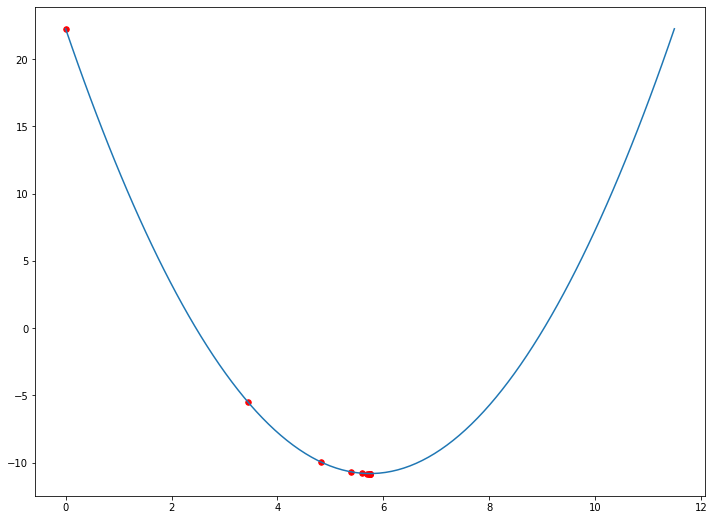

In [45]:
eta = 0.3 # 学习率

# 梯度下降5.749，算不算答案
# 5.7501
# 随机（瞎蒙）,初始值
x = np.random.randint(0,12,size = 1)[0]

# 多次while 循环，每次梯度下降，更新，记录一下上一次的值
# 比较，精确
# + 0.1；+ 0.2,；+ 1
# 一开始有差异，目的为了比较
last_x = x + 0.1

# 精确度
precision = 0.0001
print('-----------------随机x是：',x)

# 每次梯度下降，求解出来的x值，一开始随机给的
x_ = [x] # Python中列表
count = 0
while True:
    if np.abs(x - last_x) < precision: # 更新时，变化甚微，终止
        break
    # 更新，梯度下降
    # x是当前数值，赋值给上一个值
    last_x = x
    count += 1
    x = x - eta * g(x)
    x_.append(x)
#     print('+++++++++++++++更新之后的x是：',x)
print('+++++++++++++++梯度下降次数：',count)

# x1是NumPy数组
x1 = np.linspace(0,11.5,100)
y1 = f(x1)
plt.figure(figsize=(12,9))
plt.plot(x1,y1)

# 散点图
x_ = np.array(x_)
plt.scatter(x_, f(x_),color = 'red',s = 30)